In [7]:
import torch
import torch.nn as nn
import torch.functional as F

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Model(nn.Module):
    def __init__(self, in_features = 4, h1 = 7, h2 = 9, out_features = 3):
        super().__init__()
        # Layers
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)

        return x

In [9]:

torch.manual_seed(42)
model = Model()

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [11]:
df = pd.read_csv("https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv")

In [12]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [13]:
df['species'] = df['species'].replace({
    'setosa': 0.0,
    'versicolor': 1.0,
    'virginica': 2.0
})

In [14]:
X = df.drop("species", axis = 1)
y = df["species"]

In [15]:
X = X.values
y = y.values

In [16]:
y = y.astype(np.int64)

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score

In [18]:
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size = 0.3, random_state = 42)

In [19]:
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

In [20]:
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [21]:
print(df['species'].unique())
print(df['species'].dtype)

[0.0 1.0 2.0]
object


In [22]:
criterion = nn.CrossEntropyLoss()

In [31]:
optimizer = torch.optim.Adam(model.parameters()  , lr = 0.01)

In [32]:
epoch = 200
losses = []

In [33]:
for i in range(epoch):
    y_pred = model.forward(X_train)
    loss = criterion(y_pred, y_train)
    losses.append(loss.detach().numpy())
    if i % 10 == 0:
        print(f'Epoch: {i} and loss : {loss}')

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Epoch: 0 and loss : 0.6383869647979736
Epoch: 10 and loss : 0.53840571641922
Epoch: 20 and loss : 0.44617995619773865
Epoch: 30 and loss : 0.3543284237384796
Epoch: 40 and loss : 0.24857227504253387
Epoch: 50 and loss : 0.13691085577011108
Epoch: 60 and loss : 0.0918530523777008
Epoch: 70 and loss : 0.0770033523440361
Epoch: 80 and loss : 0.07035781443119049
Epoch: 90 and loss : 0.06702870875597
Epoch: 100 and loss : 0.06514829397201538
Epoch: 110 and loss : 0.06394048035144806
Epoch: 120 and loss : 0.06306593120098114
Epoch: 130 and loss : 0.06236715614795685
Epoch: 140 and loss : 0.061770252883434296
Epoch: 150 and loss : 0.06123581901192665
Epoch: 160 and loss : 0.0607435442507267
Epoch: 170 and loss : 0.06028243526816368
Epoch: 180 and loss : 0.05984586849808693
Epoch: 190 and loss : 0.05942976847290993


Text(0, 0.5, 'loss / error')

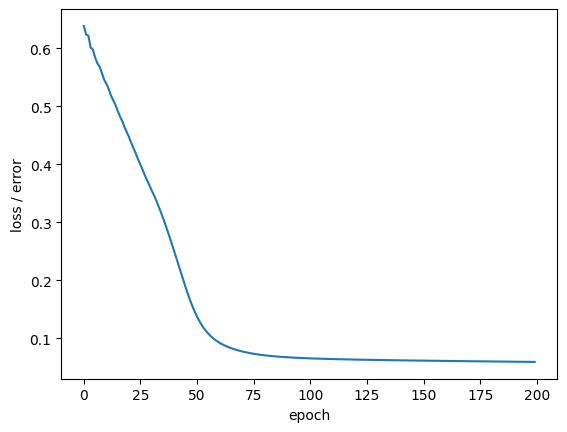

In [34]:
plt.plot(range(epoch), losses)
plt.xlabel("epoch")
plt.ylabel("loss / error")

In [35]:
model.eval()

with torch.no_grad():
    y_pred = model(X_test)
    predicted = torch.argmax(y_pred, dim=1)

accuracy = accuracy_score(y_test.numpy(), predicted.numpy())

print("Accuracy:", accuracy)

Accuracy: 1.0


In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test.numpy(),
    predicted.numpy()
)

print(cm)

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [37]:
new_iris = torch.tensor([4.7,3.3,1.3,0.2])


In [38]:
with torch.no_grad():
    print(model(new_iris))

tensor([ 4.7986, -2.8663, -5.8901])
